# Connected Markets: Predicting Stock Returns with Graph Neural Networks
**Kabir Jain, APS360 progress report notebook**

Do economic links between companies help predict next-week stock returns? This notebook builds everything
in the progress report, in order:

1. Downloads the S&P 500 company list (Wikipedia) and daily prices from 2009 (Yahoo Finance)
2. Cleans the data and picks a 100-stock universe by 2009 trading activity
3. Builds weekly samples: input = last 20 days of returns and volume changes, target = next week's rank
4. Builds the company graph: sector links and last year's correlation links
5. Trains the baselines (momentum and reversal rules, ridge regression, LSTM without a graph)
6. Trains the primary model (LSTM + relational graph attention), 3 seeds each, plus link-type ablations
7. Evaluates on the validation years (2020 to 2021) and runs the extra analyses requested in the proposal feedback

**How to run:** Runtime → Change runtime type → T4 GPU, then Runtime → Run all (allow Google Drive access).
Downloads, data and trained runs are saved to `MyDrive/Connected-Markets/`, so later runs reload them.

The test years (2022 to 2026) are not used anywhere in this notebook and stay sealed until the final report.

## 0. Setup

In [1]:
!pip -q install yfinance lxml

import os, sys, io, json, time, random, warnings
import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
warnings.filterwarnings('ignore')

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/Connected-Markets'
else:
    ROOT = os.path.abspath('./Connected-Markets')

DATA, FIG, OUT = f'{ROOT}/data', f'{ROOT}/figures', f'{ROOT}/results'
for d in (DATA, FIG, OUT):
    os.makedirs(d, exist_ok=True)

CFG = dict(
    start='2009-01-01',        # 2009 is only used as history (correlations, 2009 dollar volume)
    end='2026-11-21',          # last date downloaded
    first_sample='2010-01-01', # first decision date
    train_end='2019-12-31',
    val_end='2021-12-31',      # test = 2022 onward, NOT used in this notebook
    universe_size=100,
    window=20,                 # input length in trading days
    horizon=5,                 # predict the next 5 trading days (one week)
    corr_k=5,                  # each stock links to its 5 most correlated stocks
    corr_lookback=252,         # one year of trading days
    seeds=[0, 1, 2],
    epochs=60, patience=12, batch_weeks=16, lr=1e-3, hidden=64,
    run_ablations=True,        # also train sector-only and correlation-only GNNs
    cost_bps=10,               # trading cost per side, in basis points (0.10%)
    smoke_test=False,          # True = synthetic data, no internet (used only to test the code)
)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE, '| saving to', ROOT)
if DEVICE == 'cpu':
    print('No GPU found. It still works, just slower. Runtime → Change runtime type → T4 GPU.')

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

# One consistent, quiet chart style for every figure in the report
COLORS = {'Ridge': '#eb6834', 'LSTM': '#2a78d6', 'GNN': '#1baf7a',
          'Momentum': '#8a8984', 'Reversal': '#52514e', 'Universe': '#8a8984'}
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 220, 'savefig.bbox': 'tight',
    'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9, 'legend.fontsize': 8,
    'axes.edgecolor': '#8a8984', 'axes.labelcolor': '#0b0b0b', 'text.color': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 1.8, 'legend.frameon': False,
})
RESULTS = {'config': {k: v for k, v in CFG.items()}}
T0 = time.time()

Mounted at /content/drive
Device: cuda | saving to /content/drive/MyDrive/Connected-Markets


## 1. The company list

The current S&P 500 list comes from Wikipedia. It includes each company's **GICS sector**
(the official industry classification), which becomes the sector links in the graph, and its **CIK**
(the company's SEC ID number), which the supply-chain step will use later to find its 10-K filings.

Some companies have two share classes (for example Alphabet has GOOGL and GOOG). They are the same
company, so only one ticker per CIK is kept.

In [2]:
def make_synthetic_market(n_tickers=130, seed=7):
    # Fake market with sector structure and a small weekly reversal effect.
    # Only used when CFG['smoke_test'] is True, to test the code without internet.
    rng = np.random.default_rng(seed)
    sectors = ['Information Technology', 'Financials', 'Health Care', 'Industrials', 'Energy',
               'Consumer Discretionary', 'Consumer Staples', 'Utilities', 'Materials',
               'Real Estate', 'Communication Services']
    tick = [f'T{i:03d}' for i in range(n_tickers)]
    table = pd.DataFrame({'ticker': tick, 'name': [f'Company {t}' for t in tick],
                          'sector': [sectors[i % len(sectors)] for i in range(n_tickers)],
                          'sub_industry': 'x', 'CIK': list(range(1000, 1000 + n_tickers))})
    table.loc[1, 'CIK'] = table.loc[0, 'CIK']             # a duplicate share class
    dates = pd.bdate_range(CFG['start'], CFG['end'])
    T, N = len(dates), n_tickers
    mkt = rng.normal(0.0003, 0.011, T)
    sec_f = rng.normal(0, 0.007, (T, len(sectors)))
    sid = np.array([i % len(sectors) for i in range(N)])
    eps = rng.normal(0, 0.012, (T, N))
    r = mkt[:, None] * rng.uniform(0.6, 1.4, N) + sec_f[:, sid] + eps
    r[5:] -= 0.04 * pd.DataFrame(eps).rolling(5).sum().fillna(0).values[:-5]   # small reversal
    close = pd.DataFrame(100 * np.exp(np.cumsum(r, 0)), index=dates, columns=tick)
    vol = pd.DataFrame(rng.lognormal(14, 0.5, (T, N)) * np.linspace(0.5, 3, N), index=dates, columns=tick)
    close.iloc[:400, -3:] = np.nan                         # some stocks list late
    close.iloc[rng.integers(0, T, 40), rng.integers(0, N, 40)] = np.nan  # random gaps
    return table, {'close': close, 'volume': vol, 'failed': []}

def get_constituents():
    path = f'{DATA}/sp500_constituents.csv'
    if os.path.exists(path):
        return pd.read_csv(path)
    if CFG['smoke_test']:
        table, _ = make_synthetic_market()
    else:
        import requests
        url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
        html = requests.get(url, headers={'User-Agent': 'Mozilla/5.0 (APS360 student project)'}, timeout=30).text
        try:
            table = pd.read_html(io.StringIO(html), attrs={'id': 'constituents'})[0]
        except Exception:
            table = pd.read_html(io.StringIO(html))[0]
        table = table.rename(columns={'Symbol': 'ticker', 'Security': 'name', 'GICS Sector': 'sector',
                                      'GICS Sub-Industry': 'sub_industry'})
        table['ticker'] = table['ticker'].astype(str).str.replace('.', '-', regex=False)  # BRK.B -> BRK-B
        table = table[['ticker', 'name', 'sector', 'sub_industry', 'CIK']]
    table.to_csv(path, index=False)
    return table

const = get_constituents()
n_listed = len(const)
const = const.drop_duplicates('CIK', keep='first').reset_index(drop=True)
print(f'{n_listed} tickers listed, {len(const)} companies after removing duplicate share classes')
const.head()

503 tickers listed, 500 companies after removing duplicate share classes


,ticker,name,sector,sub_industry,CIK
0,MMM,3M,Industrials,Industrial Conglomerates,66740
1,AOS,A. O. Smith,Industrials,Building Products,91142
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,1800
3,ABBV,AbbVie,Health Care,Biotechnology,1551152
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,1467373


## 2. Download daily prices

Prices come from Yahoo Finance through the `yfinance` library, downloaded in small batches with retries
(Yahoo limits how fast you can download). Prices are **adjusted** for splits and dividends, so a 2-for-1 split
does not look like a 50% crash.

The raw download is saved to Drive, so this only happens once.

In [3]:
def _extract(df, t):
    # yfinance returns columns as (ticker, field) or (field, ticker) depending on settings
    if df is None or df.empty:
        return None
    if isinstance(df.columns, pd.MultiIndex):
        if t in df.columns.get_level_values(0):
            sub = df[t]
        elif t in df.columns.get_level_values(1):
            sub = df.xs(t, axis=1, level=1)
        else:
            return None
    else:
        sub = df
    if not {'Close', 'Volume'} <= set(sub.columns):
        return None
    sub = sub[['Close', 'Volume']].dropna(how='all')
    return sub if len(sub) else None

def download_prices(tickers):
    path = f'{DATA}/prices_raw.pkl'
    if os.path.exists(path):
        return pd.read_pickle(path)
    if CFG['smoke_test']:
        _, raw = make_synthetic_market()
        pd.to_pickle(raw, path)
        return raw
    import yfinance as yf
    frames, todo = {}, list(tickers)
    for attempt in range(3):
        failed = []
        chunks = [todo[i:i + 25] for i in range(0, len(todo), 25)]
        for ci, ch in enumerate(chunks):
            try:
                df = yf.download(ch, start=CFG['start'], end=CFG['end'], auto_adjust=True,
                                 group_by='ticker', progress=False, threads=True)
            except Exception as e:
                print('  batch error:', str(e)[:80]); df = None
            for t in ch:
                sub = _extract(df, t)
                if sub is None: failed.append(t)
                else: frames[t] = sub
            print(f'  pass {attempt+1}: batch {ci+1}/{len(chunks)} done, {len(frames)} tickers so far', end='\r')
            time.sleep(1.0)
        print()
        if not failed: break
        print(f'  {len(failed)} tickers failed, retrying in {20*(attempt+1)}s')
        time.sleep(20 * (attempt + 1)); todo = failed
    def strip_tz(s):
        s.index = pd.to_datetime(s.index).tz_localize(None) if getattr(s.index, 'tz', None) else pd.to_datetime(s.index)
        return s
    close = pd.DataFrame({t: strip_tz(f['Close']) for t, f in frames.items()})
    volume = pd.DataFrame({t: strip_tz(f['Volume']) for t, f in frames.items()})
    raw = {'close': close, 'volume': volume, 'failed': failed}
    pd.to_pickle(raw, path)
    return raw

raw = download_prices(const['ticker'].tolist())
print(f"Downloaded {raw['close'].shape[1]} tickers, {raw['close'].shape[0]} days. Failed: {raw['failed']}")

Downloaded 500 tickers, 4500 days. Failed: []


## 3. Clean the data and choose the 100-stock universe

Cleaning steps, in order:

1. **Trading calendar:** keep only days when most stocks traded (drops stray holiday rows).
2. **Bad values:** prices ≤ 0 become missing.
3. **Small gaps:** a missing price is filled with the previous day's price, for at most 3 days.
4. **Full history required:** a stock must have a price on the first trading day of 2009 and no missing
   days after filling. Stocks that listed later (for example Meta in 2012) are dropped.
5. **Universe:** the 100 stocks with the highest average daily **dollar volume** (price × shares traded) during 2009.
   This measures how big and active a company was *at the start of the sample*, using only information
   available then. Picking by today's size would quietly favour companies we already know became winners.

In [4]:
close = raw['close'].sort_index().copy()
volume = raw['volume'].reindex_like(close).copy()
close = close.where(close > 0)

coverage = close.notna().mean(axis=1)
cal = close.index[(coverage > 0.5) & (close.index >= CFG['start'])]
close, volume = close.loc[cal], volume.loc[cal]

close_f = close.ffill(limit=3)
volume_f = volume.ffill(limit=3).fillna(0)

first_day = close_f.index[0]
full = close_f.columns[close_f.notna().all() & close_f.loc[first_day].notna()]
dropped_history = sorted(set(close_f.columns) - set(full))
close_f, volume_f = close_f[full], volume_f[full]
gaps_filled = int(close[full].isna().sum().sum())   # missing prices in kept stocks, all filled

dv_2009 = (close_f * volume_f).loc[:'2009-12-31'].mean()
universe = dv_2009.sort_values(ascending=False).index[:CFG['universe_size']].tolist()
close_u, vol_u = close_f[universe], volume_f[universe]
meta = const.set_index('ticker').loc[universe].reset_index()

r_daily = np.log(close_u).diff()
extreme = int((r_daily.abs() > np.log(1.5)).sum().sum())

print(f'Trading days kept: {len(cal)} ({cal[0].date()} to {cal[-1].date()})')
print(f'Stocks with full history: {len(full)} | dropped for short history: {len(dropped_history)}')
print(f'Gaps filled in kept stocks: {gaps_filled} | daily moves over 50%: {extreme}')
print('Universe sectors:'); print(meta['sector'].value_counts().to_string())

RESULTS['data'] = dict(
    n_listed=int(n_listed), n_companies=int(len(const)), n_downloaded=int(raw['close'].shape[1]),
    n_failed=len(raw['failed']), n_full_history=int(len(full)), n_dropped_history=len(dropped_history),
    n_days=int(len(cal)), first_day=str(cal[0].date()), last_day=str(cal[-1].date()),
    gaps_filled=gaps_filled, extreme_moves=extreme, universe=universe,
    sector_counts=meta['sector'].value_counts().to_dict())
meta.to_csv(f'{DATA}/universe.csv', index=False)

Trading days kept: 4500 (2009-01-02 to 2026-11-20)
Stocks with full history: 412 | dropped for short history: 88
Gaps filled in kept stocks: 0 | daily moves over 50%: 10
Universe sectors:
sector
Financials                20
Health Care               16
Information Technology    14
Consumer Discretionary    12
Industrials               11
Energy                     9
Consumer Staples           8
Communication Services     5
Materials                  4
Real Estate                1


## 4. Turn prices into weekly training samples

For every stock and every week:

- **Input:** the last 20 trading days of two numbers per day: the **daily log return** (how much the price moved)
  and the **daily change in log volume** (whether trading suddenly got busier or quieter).
- **Target:** the stock's return over the **next 5 trading days**.

Samples are taken every 5 trading days, so the weekly targets never overlap.

The model's job is to **rank** stocks against each other each week, not to guess whether the whole market rises.
So the training target is each stock's rank that week, scaled from −0.5 (worst) to +0.5 (best).
For accuracy, a stock is labelled **"outperform"** if its return beats that week's median, which makes the two
classes exactly 50/50 every week.

**Splits:** train = 2010 to 2019, validation = 2020 to 2021, test = 2022 onward.
A sample is dropped if its 5-day target crosses into the next split, so no label leaks across a boundary.
Inputs are standardized using **training-period statistics only**.

In [5]:
W, H = CFG['window'], CFG['horizon']
dates = close_u.index
R = np.log(close_u.values[1:] / close_u.values[:-1])                 # [T-1, N]
V = np.diff(np.log1p(vol_u.values), axis=0).clip(-5, 5)
R = np.vstack([np.full((1, R.shape[1]), np.nan), R])                # align with dates
V = np.vstack([np.full((1, V.shape[1]), np.nan), V])

start_idx = max(int(np.searchsorted(dates, pd.Timestamp(CFG['first_sample']))), W)
dec_idx = np.arange(start_idx, len(dates) - H, H)

def split_of(d):
    return 'train' if d <= pd.Timestamp(CFG['train_end']) else ('val' if d <= pd.Timestamp(CFG['val_end']) else 'test')

keep = [t for t in dec_idx if split_of(dates[t]) == split_of(dates[t + H])]
dec_idx = np.array(keep)
X = np.stack([np.stack([R[t - W + 1:t + 1], V[t - W + 1:t + 1]], axis=-1) for t in dec_idx])  # [K, W, N, 2]
X = X.transpose(0, 2, 1, 3).astype(np.float32)                                              # [K, N, W, 2]
y_ret = np.stack([R[t + 1:t + H + 1].sum(0) for t in dec_idx]).astype(np.float32)           # [K, N]
dec_dates = dates[dec_idx]
split = np.array([split_of(d) for d in dec_dates])

ranks = y_ret.argsort(1).argsort(1).astype(np.float32)
y_rank = ranks / (y_ret.shape[1] - 1) - 0.5
y_cls = (y_ret > np.median(y_ret, axis=1, keepdims=True)).astype(np.int64)

tr = split == 'train'
mu = X[tr].reshape(-1, 2).mean(0); sd = X[tr].reshape(-1, 2).std(0)
Xs = ((X - mu) / sd).clip(-6, 6).astype(np.float32)
assert np.isfinite(Xs).all() and np.isfinite(y_ret).all()

counts = {s: int((split == s).sum()) for s in ['train', 'val', 'test']}
cls_counts = {s: {'outperform': int(y_cls[split == s].sum()),
                  'underperform': int((1 - y_cls[split == s]).sum())} for s in ['train', 'val']}
print('Weeks per split:', counts)
print('Stock-week samples per class:', cls_counts)
RESULTS['data'].update(weeks=counts, class_counts=cls_counts,
                       stock_weeks={s: counts[s] * len(universe) for s in counts},
                       feature_mean=mu.tolist(), feature_std=sd.tolist(),
                       first_decision=str(dec_dates[0].date()), last_val_decision=str(dec_dates[split == 'val'][-1].date()))

Weeks per split: {'train': 503, 'val': 100, 'test': 244}
Stock-week samples per class: {'train': {'outperform': 25150, 'underperform': 25150}, 'val': {'outperform': 5000, 'underperform': 5000}}


## 5. Build the company graph

Each stock is a node. Two kinds of links (edges) for now:

- **Sector links:** two stocks are linked if they share a GICS sector (for example JPMorgan and Bank of America).
- **Correlation links:** each stock links to the 5 stocks whose daily returns moved most like its own over the
  **previous** year. This is recomputed every January using only past data, so the graph for 2015 is built from 2014 prices.

**Supply-chain links** from 10-K filings are the next step after this report. They plug into the same model
as a third edge type.

In [6]:
N = len(universe)
sectors = meta['sector'].astype(str).to_numpy(dtype=object)
A_sector = (sectors[:, None] == sectors[None, :]).astype(np.float32)
np.fill_diagonal(A_sector, 0)

years = sorted({d.year for d in dec_dates})
A_corr = {}
for Y in years:
    end = int(np.searchsorted(dates, pd.Timestamp(f'{Y}-01-01')))      # first day of year Y (excluded)
    hist = R[max(1, end - CFG['corr_lookback']):end]
    C = np.corrcoef(hist.T); np.fill_diagonal(C, -np.inf)
    A = np.zeros((N, N), np.float32)
    top = np.argsort(-C, axis=1)[:, :CFG['corr_k']]
    A[np.repeat(np.arange(N), CFG['corr_k']), top.ravel()] = 1
    A_corr[Y] = np.maximum(A, A.T)                                      # make links two-way
year_list = years
A_corr_stack = np.stack([A_corr[Y] for Y in year_list])                 # [n_years, N, N]
week_year = np.array([year_list.index(d.year) for d in dec_dates])

n_sector_edges = int(A_sector.sum() // 2)
corr_edges = [int(A_corr[Y].sum() // 2) for Y in year_list]
overlap = [float((A_corr[Y] * A_sector).sum() / A_corr[Y].sum()) for Y in year_list]
print(f'Sector links: {n_sector_edges} | correlation links per year: {min(corr_edges)} to {max(corr_edges)}')
print(f'Share of correlation links that are inside the same sector: {np.mean(overlap):.0%}')
RESULTS['graph'] = dict(n_nodes=N, sector_edges=n_sector_edges, corr_edges_min=min(corr_edges),
                        corr_edges_max=max(corr_edges), corr_edges_mean=float(np.mean(corr_edges)),
                        corr_same_sector_share=float(np.mean(overlap)),
                        sector_avg_degree=float(A_sector.sum(1).mean()),
                        corr_avg_degree=float(np.mean([A_corr[Y].sum(1).mean() for Y in year_list])))

np.savez_compressed(f'{DATA}/dataset.npz', X=Xs, y_ret=y_ret, y_rank=y_rank, y_cls=y_cls,
                    dates=dec_dates.astype(str), split=split, tickers=np.array(universe),
                    sectors=sectors, A_sector=A_sector, A_corr=A_corr_stack, week_year=week_year,
                    years=np.array(year_list))
print('Saved dataset to Drive.')

Sector links: 602 | correlation links per year: 375 to 432
Share of correlation links that are inside the same sector: 50%
Saved dataset to Drive.


### Figures for the data section

1. One cleaned training sample: what the model actually sees for one stock in one week.
2. The company graph as a grid: stocks sorted by sector, a dot wherever two stocks are linked.

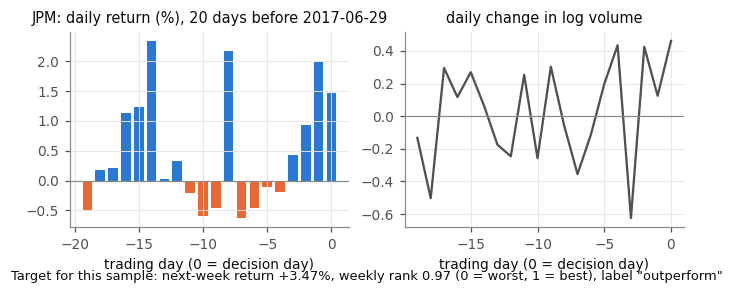

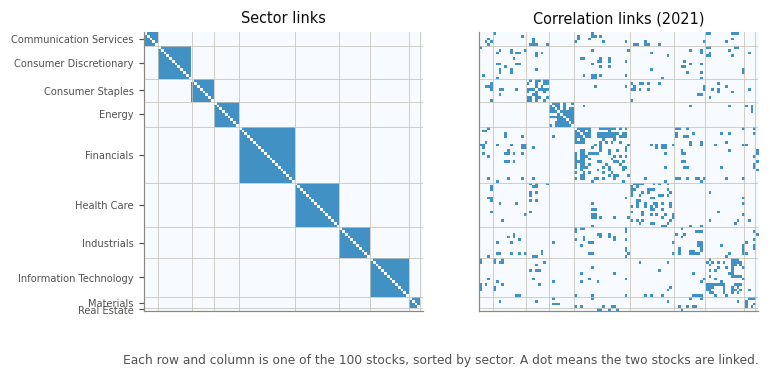

In [7]:
# 1) An example training sample
ex_t = 'JPM' if 'JPM' in universe else universe[0]
ex_n = universe.index(ex_t)
tr_idx = np.where(split == 'train')[0]
ex_k = tr_idx[len(tr_idx) * 3 // 4]
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.3))
days = np.arange(-W + 1, 1)
ret = X[ex_k, ex_n, :, 0] * 100
ax[0].bar(days, ret, color=np.where(ret >= 0, '#2a78d6', '#eb6834'), width=0.75)
ax[0].axhline(0, color='#8a8984', lw=0.8)
ax[0].set_title(f'{ex_t}: daily return (%), 20 days before {dec_dates[ex_k].date()}')
ax[0].set_xlabel('trading day (0 = decision day)')
ax[1].plot(days, X[ex_k, ex_n, :, 1], color='#52514e', lw=1.5)
ax[1].axhline(0, color='#8a8984', lw=0.8)
ax[1].set_title('daily change in log volume')
ax[1].set_xlabel('trading day (0 = decision day)')
lab = 'outperform' if y_cls[ex_k, ex_n] else 'underperform'
fig.text(0.5, -0.1, f'Target for this sample: next-week return {y_ret[ex_k, ex_n]*100:+.2f}%, '
         f'weekly rank {y_rank[ex_k, ex_n]+0.5:.2f} (0 = worst, 1 = best), label "{lab}"',
         ha='center', fontsize=8.5)
fig.savefig(f'{FIG}/example_sample.png'); plt.show()
RESULTS['example'] = dict(ticker=ex_t, date=str(dec_dates[ex_k].date()),
                          target_return=float(y_ret[ex_k, ex_n]), label=lab)

# 2) The graph as a sorted adjacency grid
order = np.argsort(sectors, kind='stable')
Yshow = 2021 if 2021 in A_corr else year_list[-1]
fig, ax = plt.subplots(1, 2, figsize=(7.2, 3.4))
for a, M, title in [(ax[0], A_sector, 'Sector links'), (ax[1], A_corr[Yshow], f'Correlation links ({Yshow})')]:
    Ms = M[np.ix_(order, order)]
    a.imshow(Ms, cmap='Blues', vmin=0, vmax=1.6, interpolation='nearest')
    a.set_title(title); a.grid(False)
    bounds = np.where(sectors[order][1:] != sectors[order][:-1])[0] + 0.5
    for b in bounds:
        a.axhline(b, color='#c3c2b7', lw=0.5); a.axvline(b, color='#c3c2b7', lw=0.5)
    a.set_xticks([]); a.set_yticks([])
sec_sorted = sectors[order]
mids = [np.mean(np.where(sec_sorted == s)[0]) for s in pd.unique(sec_sorted)]
ax[0].set_yticks(mids); ax[0].set_yticklabels(pd.unique(sec_sorted), fontsize=6.5)
fig.text(0.5, -0.02, 'Each row and column is one of the 100 stocks, sorted by sector. A dot means the two stocks are linked.',
         ha='center', fontsize=8, color='#52514e')
fig.savefig(f'{FIG}/graph_adjacency.png'); plt.show()

## 6. Baselines

**Simple rules (no learning):**
- **Momentum:** stocks that rose most over the last 20 days keep rising.
- **Reversal:** stocks that rose most over the last 5 days fall back next week.

**Ridge regression:** a linear model on the same 20 daily returns, with the regularization strength chosen on validation.
Its weights show how much each past day matters.

### How results are measured (same for every model)
- **IC (information coefficient):** each week, the rank correlation between predicted and actual returns, averaged over weeks.
  0 = no skill. In real markets, 0.02 to 0.05 is considered useful.
- **Accuracy:** how often the model correctly says whether a stock beats the weekly median (50% = guessing).
- **Top-10 portfolio:** each week, buy the 10 stocks the model likes most. We report the yearly return **above the
  average of all 100 stocks**, and its Sharpe ratio (return per unit of risk), before and after 0.10% trading costs per trade.

Ridge alpha chosen on validation: 1000
Momentum  val IC +0.0160 (t=+0.65) | acc 0.503 | excess/yr +4.4% | Sharpe +0.21
Reversal  val IC -0.0005 (t=-0.02) | acc 0.504 | excess/yr -3.4% | Sharpe -0.13
Ridge     val IC -0.0379 (t=-1.67) | acc 0.488 | excess/yr -16.0% | Sharpe -0.82


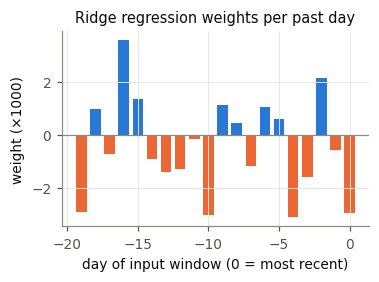

In [8]:
def evaluate(pred, mask, top_k=10):
    P, Yr, Yc = pred[mask], y_ret[mask], y_cls[mask]
    ics = np.array([spearmanr(p, r).correlation for p, r in zip(P, Yr)])
    acc = float(np.mean([( (p > np.median(p)) == c ).mean() for p, c in zip(P, Yc)]))
    simple = np.expm1(Yr)
    picks = np.argsort(-P, axis=1)[:, :top_k]
    port = np.take_along_axis(simple, picks, 1).mean(1)
    excess = port - simple.mean(1)
    turnover = np.r_[1.0, [1 - len(set(a) & set(b)) / top_k for a, b in zip(picks[1:], picks[:-1])]]
    net = excess - turnover * 2 * CFG['cost_bps'] / 1e4
    ann = lambda x: float(x.mean() * 52)
    shp = lambda x: float(x.mean() / (x.std() + 1e-12) * np.sqrt(52))
    return dict(ic=float(np.nanmean(ics)), ic_t=float(np.nanmean(ics) / (np.nanstd(ics) + 1e-12) * np.sqrt(len(ics))),
                ic_hit=float(np.mean(ics > 0)), acc=acc,
                excess_ann=ann(excess), sharpe=shp(excess), excess_ann_net=ann(net), sharpe_net=shp(net),
                turnover=float(turnover[1:].mean()),
                weekly_ic=ics.tolist(), cum_excess=np.cumsum(excess).tolist())

tr, va = split == 'train', split == 'val'
preds, metrics = {}, {}

preds['Momentum'] = X[:, :, :, 0].sum(2)
preds['Reversal'] = -X[:, :, -5:, 0].sum(2)

from sklearn.linear_model import Ridge
F_ret = Xs[:, :, :, 0]                      # standardized returns [K, N, 20]
best = None
for alpha in [0.1, 1, 10, 100, 1000, 1e4]:
    m = Ridge(alpha=alpha).fit(F_ret[tr].reshape(-1, W), y_rank[tr].ravel())
    p = m.predict(F_ret.reshape(-1, W)).reshape(y_rank.shape)
    ic = evaluate(p, va)['ic']
    if best is None or ic > best[0]: best = (ic, alpha, m, p)
_, ridge_alpha, ridge, preds['Ridge'] = best
print('Ridge alpha chosen on validation:', ridge_alpha)

for name in ['Momentum', 'Reversal', 'Ridge']:
    metrics[name] = {'train': evaluate(preds[name], tr), 'val': evaluate(preds[name], va)}
    v = metrics[name]['val']
    print(f"{name:9s} val IC {v['ic']:+.4f} (t={v['ic_t']:+.2f}) | acc {v['acc']:.3f} | excess/yr {v['excess_ann']:+.1%} | Sharpe {v['sharpe']:+.2f}")
RESULTS['ridge'] = dict(alpha=ridge_alpha, coef_by_lag=ridge.coef_.tolist())

fig, ax = plt.subplots(figsize=(3.6, 2.3))
lags = np.arange(-W + 1, 1)
ax.bar(lags, ridge.coef_ * 1e3, color=np.where(ridge.coef_ >= 0, '#2a78d6', '#eb6834'), width=0.75)
ax.axhline(0, color='#8a8984', lw=0.8)
ax.set_xlabel('day of input window (0 = most recent)'); ax.set_ylabel('weight (×1000)')
ax.set_title('Ridge regression weights per past day')
fig.savefig(f'{FIG}/ridge_weights.png'); plt.show()

## 7. The neural networks

**LSTM encoder (used by both models):** reads each stock's 20 days, one day at a time, and summarizes them
into 64 numbers.

**Graph attention layer (GNN only):** each stock looks at the stocks it is linked to. For every link it learns an
**attention weight** (how much to listen to that neighbour), separately for sector links and correlation links.
It adds the weighted information to its own summary. A residual connection keeps the stock's own summary,
so the graph can only add information.

**Head:** two small layers turn each stock's final summary into a score. Higher score = expected to do better next week.

**LSTM baseline** = the same network with the graph layers removed. Comparing the two isolates what the graph adds.

Training: mean squared error on the weekly rank, Adam optimizer, 16 weeks per batch, early stopping on validation IC,
3 random seeds per model (results are averaged because single runs are noisy).

In [9]:
class LSTMEncoder(nn.Module):
    def __init__(self, n_feat=2, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, hidden, layers, batch_first=True, dropout=dropout)
    def forward(self, x):                      # x: [batch, 20, 2]
        out, _ = self.lstm(x)
        return out[:, -1]                      # summary after the last day: [batch, hidden]

class RelationalGAT(nn.Module):
    # Graph attention with a separate set of weights for each link type.
    def __init__(self, d, n_rel, heads=2, dropout=0.1):
        super().__init__()
        self.h, self.dh, self.R = heads, d // heads, n_rel
        self.W = nn.Parameter(torch.randn(n_rel, heads, d, self.dh) * d ** -0.5)
        self.a_src = nn.Parameter(torch.randn(n_rel, heads, self.dh) * 0.1)
        self.a_dst = nn.Parameter(torch.randn(n_rel, heads, self.dh) * 0.1)
        self.self_lin = nn.Linear(d, d)
        self.norm = nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)
        self.last_alpha = None
    def forward(self, h, A):                   # h: [B, N, d], A: [B, R, N, N] (1 = linked)
        B, N, d = h.shape
        Wh = torch.einsum('bnd,rhde->brhne', h, self.W)                     # [B, R, H, N, dh]
        s_src = (Wh * self.a_src[None, :, :, None]).sum(-1)                  # [B, R, H, N]
        s_dst = (Wh * self.a_dst[None, :, :, None]).sum(-1)
        e = F.leaky_relu(s_dst.unsqueeze(-1) + s_src.unsqueeze(-2), 0.2)     # [B, R, H, N_i, N_j]
        mask = A.unsqueeze(2) > 0
        alpha = torch.softmax(e.masked_fill(~mask, -1e9), dim=-1) * mask      # zero for non-links
        self.last_alpha = alpha.detach()
        msg = torch.matmul(self.drop(alpha), Wh)                             # [B, R, H, N, dh]
        msg = msg.permute(0, 3, 1, 2, 4).reshape(B, N, self.R, d).sum(2)      # combine heads, sum link types
        return self.norm(h + self.drop(F.elu(self.self_lin(h) + msg)))

class StockModel(nn.Module):
    def __init__(self, n_rel=0, hidden=64, gnn_layers=2):
        super().__init__()
        self.enc = LSTMEncoder(2, hidden)
        self.gnn = nn.ModuleList([RelationalGAT(hidden, n_rel) for _ in range(gnn_layers)]) if n_rel else nn.ModuleList()
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Dropout(0.1), nn.Linear(32, 1))
    def forward(self, x, A=None):              # x: [B, N, 20, 2]
        B, N, Wn, Fd = x.shape
        h = self.enc(x.reshape(B * N, Wn, Fd)).reshape(B, N, -1)
        for layer in self.gnn:
            h = layer(h, A)
        return self.head(h).squeeze(-1)        # [B, N] score per stock

Xt = torch.tensor(Xs); Yt = torch.tensor(y_rank)
A_sec_t = torch.tensor(A_sector); A_corr_t = torch.tensor(A_corr_stack); wy_t = torch.tensor(week_year)

def adjacency(idx, rels):
    mats = []
    for r in rels:
        if r == 'sector': mats.append(A_sec_t.expand(len(idx), N, N))
        if r == 'corr': mats.append(A_corr_t[wy_t[idx]])
    return torch.stack(mats, 1) if mats else None

@torch.no_grad()
def predict(model, rels, idx_all=None):
    model.eval(); out = []
    idx_all = np.arange(len(Xt)) if idx_all is None else idx_all
    for i in range(0, len(idx_all), 64):
        idx = torch.tensor(idx_all[i:i + 64])
        A = adjacency(idx, rels)
        out.append(model(Xt[idx].to(DEVICE), None if A is None else A.to(DEVICE)).cpu())
    return torch.cat(out).numpy()

def train_model(rels, seed):
    set_seed(seed)
    model = StockModel(n_rel=len(rels), hidden=CFG['hidden']).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=CFG['lr'], weight_decay=1e-5)
    tr_idx, va_idx = np.where(tr)[0], np.where(va)[0]
    hist = {'train_loss': [], 'val_loss': [], 'val_ic': []}
    best_ic, best_state, wait = -np.inf, None, 0
    for ep in range(CFG['epochs']):
        model.train(); np.random.shuffle(tr_idx); losses = []
        for i in range(0, len(tr_idx), CFG['batch_weeks']):
            idx = torch.tensor(tr_idx[i:i + CFG['batch_weeks']])
            A = adjacency(idx, rels)
            pred = model(Xt[idx].to(DEVICE), None if A is None else A.to(DEVICE))
            loss = F.mse_loss(pred, Yt[idx].to(DEVICE))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
            losses.append(loss.item())
        pv = predict(model, rels, va_idx)
        val_loss = float(np.mean((pv - y_rank[va_idx]) ** 2))
        val_ic = float(np.nan_to_num(np.nanmean([spearmanr(p, r).correlation for p, r in zip(pv, y_ret[va_idx])]), nan=-1.0))
        hist['train_loss'].append(float(np.mean(losses))); hist['val_loss'].append(val_loss); hist['val_ic'].append(val_ic)
        if val_ic > best_ic:
            best_ic, best_state, wait, best_ep = val_ic, {k: v.detach().clone() for k, v in model.state_dict().items()}, 0, ep
        else:
            wait += 1
            if wait >= CFG['patience']: break
    model.load_state_dict(best_state)
    hist['best_epoch'] = best_ep
    return model, hist

n_params = lambda m: sum(p.numel() for p in m.parameters())
print('Parameters  LSTM baseline:', n_params(StockModel(0)), '| GNN (2 link types):', n_params(StockModel(2)))

Parameters  LSTM baseline: 52801 | GNN (2 link types): 78273


**Training note:** this cell trains every model (LSTM, full GNN and two link-type ablations, 3 seeds each) and saves each run to `results/runs.pkl`. The first full run took about 4 minutes on a T4 GPU and printed one line per run. Later runs reload the saved models instead of retraining, so the numbers stay identical to the progress report. Delete `results/runs.pkl` to retrain from scratch.

In [10]:
variants = {'LSTM': [], 'GNN': ['sector', 'corr']}
if CFG['run_ablations']:
    variants.update({'GNN (sector only)': ['sector'], 'GNN (correlation only)': ['corr']})

runs = {}
ckpt_path = f'{OUT}/runs.pkl'
if os.path.exists(ckpt_path):
    runs = pd.read_pickle(ckpt_path)
for name, rels in variants.items():
    for seed in CFG['seeds']:
        key = f'{name}|{seed}'
        if key in runs: continue
        t1 = time.time()
        model, hist = train_model(rels, seed)
        p = predict(model, rels)
        runs[key] = dict(pred=p, hist=hist, n_params=n_params(model), minutes=(time.time() - t1) / 60)
        if name == 'GNN' and seed == CFG['seeds'][0]:
            torch.save(model.state_dict(), f'{OUT}/gnn_seed0.pt')
        v = evaluate(p, va)
        print(f"{key:28s} best epoch {hist['best_epoch']:2d} | val IC {v['ic']:+.4f} | acc {v['acc']:.3f} | {runs[key]['minutes']:.1f} min")
        pd.to_pickle(runs, ckpt_path)          # save after every run, so a disconnect loses at most one run

## 8. Results

Each neural model's score is averaged over its 3 seeds (an "ensemble"). The table also shows the spread across seeds,
which tells you how much of a difference is real versus luck.

,train IC,val IC,val IC t-stat,val acc,excess return/yr,Sharpe,Sharpe after costs,seed IC std
model,,,,,,,,
Momentum,-0.0056,+0.0160,+0.65,0.503,+4.4%,+0.21,-0.01,+nan
Reversal,+0.0106,-0.0005,-0.02,0.504,-3.4%,-0.13,-0.48,+nan
Ridge,+0.0279,-0.0379,-1.67,0.488,-16.0%,-0.82,-1.31,+nan
LSTM,+0.0106,+0.0058,+0.23,0.505,+6.3%,+0.33,-0.14,+0.0042
GNN,+0.0108,+0.0117,+0.62,0.509,-0.3%,-0.02,-0.50,+0.0100
GNN (sector only),+0.0143,+0.0109,+0.60,0.505,+15.9%,+0.99,+0.48,+0.0003
GNN (correlation only),+0.0128,+0.0195,+0.96,0.509,+12.9%,+0.70,+0.23,+0.0036


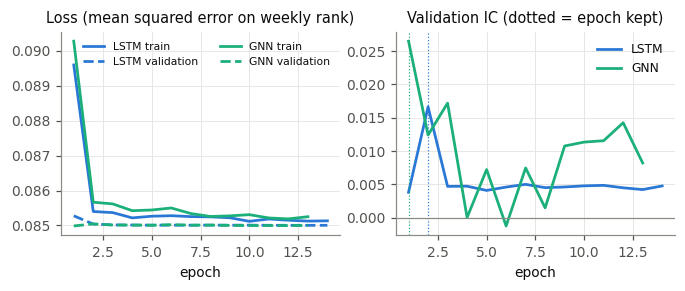

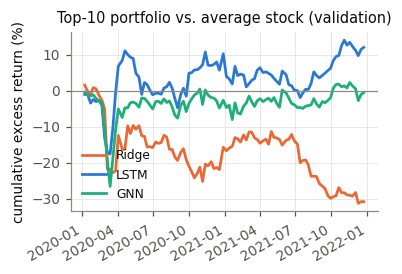

In [11]:
for name in variants:
    ps = [runs[f'{name}|{s}']['pred'] for s in CFG['seeds']]
    preds[name] = np.mean(ps, 0)
    metrics[name] = {'train': evaluate(preds[name], tr), 'val': evaluate(preds[name], va)}
    seed_ics = [evaluate(p, va)['ic'] for p in ps]
    metrics[name]['val']['ic_seed_mean'] = float(np.mean(seed_ics))
    metrics[name]['val']['ic_seed_std'] = float(np.std(seed_ics))
    metrics[name]['n_params'] = runs[f'{name}|{CFG["seeds"][0]}']['n_params']
    metrics[name]['best_epochs'] = [runs[f'{name}|{s}']['hist']['best_epoch'] for s in CFG['seeds']]

rows = []
for name in ['Momentum', 'Reversal', 'Ridge'] + list(variants):
    v, t = metrics[name]['val'], metrics[name]['train']
    rows.append({'model': name, 'train IC': t['ic'], 'val IC': v['ic'], 'val IC t-stat': v['ic_t'],
                 'val acc': v['acc'], 'excess return/yr': v['excess_ann'], 'Sharpe': v['sharpe'],
                 'Sharpe after costs': v['sharpe_net'], 'seed IC std': v.get('ic_seed_std', np.nan)})
table = pd.DataFrame(rows).set_index('model')
try:
    display(table.style.format('{:+.4f}', subset=['train IC', 'val IC', 'seed IC std'])
            .format('{:+.2f}', subset=['val IC t-stat', 'Sharpe', 'Sharpe after costs'])
            .format('{:.3f}', subset=['val acc']).format('{:+.1%}', subset=['excess return/yr']))
except Exception:
    print(table.round(4).to_string())
table.to_csv(f'{OUT}/results_table.csv')

# Learning curves (seed 0)
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.4))
for name in ['LSTM', 'GNN']:
    h = runs[f'{name}|{CFG["seeds"][0]}']['hist']
    ep = np.arange(1, len(h['train_loss']) + 1)
    ax[0].plot(ep, h['train_loss'], color=COLORS[name], label=f'{name} train')
    ax[0].plot(ep, h['val_loss'], color=COLORS[name], ls='--', label=f'{name} validation')
    ax[1].plot(ep, h['val_ic'], color=COLORS[name], label=name)
    ax[1].axvline(h['best_epoch'] + 1, color=COLORS[name], lw=0.8, ls=':')
ax[0].set_title('Loss (mean squared error on weekly rank)'); ax[0].set_xlabel('epoch'); ax[0].legend(ncol=2, fontsize=7)
ax[1].set_title('Validation IC (dotted = epoch kept)'); ax[1].set_xlabel('epoch'); ax[1].axhline(0, color='#8a8984', lw=0.8)
ax[1].legend()
fig.savefig(f'{FIG}/learning_curves.png'); plt.show()

# Cumulative return above the 100-stock average, validation years
fig, ax = plt.subplots(figsize=(3.6, 2.4))
vd = pd.to_datetime(dec_dates[va])
for name in ['Ridge', 'LSTM', 'GNN']:
    ax.plot(vd, np.array(metrics[name]['val']['cum_excess']) * 100, color=COLORS[name], label=name)
ax.axhline(0, color='#8a8984', lw=0.8)
ax.set_title('Top-10 portfolio vs. average stock (validation)'); ax.set_ylabel('cumulative excess return (%)')
ax.legend(); fig.autofmt_xdate()
fig.savefig(f'{FIG}/val_cumulative.png'); plt.show()

## 9. A look inside the GNN: who does each stock listen to?

The attention weights show which linked companies the trained GNN relies on most. Below, for a few well-known
stocks, the neighbours with the highest average attention over the validation weeks. If the model learned something
sensible, a bank should listen mostly to other banks, an oil company to other oil companies, and so on.

In [12]:
gnn = StockModel(n_rel=2, hidden=CFG['hidden']).to(DEVICE)
gnn.load_state_dict(torch.load(f'{OUT}/gnn_seed0.pt', map_location=DEVICE)); gnn.eval()
va_idx = np.where(va)[0]
att_sum = {r: np.zeros((N, N)) for r in ['sector', 'corr']}
with torch.no_grad():
    for i in range(0, len(va_idx), 32):
        idx = torch.tensor(va_idx[i:i + 32])
        gnn(Xt[idx].to(DEVICE), adjacency(idx, ['sector', 'corr']).to(DEVICE))
        a = gnn.gnn[0].last_alpha.mean(2).sum(0).cpu().numpy()          # first layer, average heads, sum weeks
        att_sum['sector'] += a[0]; att_sum['corr'] += a[1]
att = {r: att_sum[r] / len(va_idx) for r in att_sum}

names = dict(zip(meta['ticker'], meta['name']))
showcase = [t for t in ['JPM', 'XOM', 'AAPL', 'PFE', 'WMT', 'BA'] if t in universe][:4] or universe[:4]
neighbours = {}
for t in showcase:
    i = universe.index(t)
    combined = att['corr'][i] + att['sector'][i]
    top = np.argsort(-combined)[:3]
    neighbours[t] = [(universe[j], float(combined[j]), 'corr' if att['corr'][i, j] >= att['sector'][i, j] else 'sector')
                     for j in top if combined[j] > 0]
    print(f"{t:5s} ({sectors[i]}): " + ', '.join(f"{n} {w:.2f} [{k}]" for n, w, k in neighbours[t]))
RESULTS['attention_examples'] = neighbours

# How concentrated is attention? (uniform attention = the model did not learn to prefer anyone)
def concentration(M, A):
    deg = A.sum(1); top = np.sort(M, 1)[:, -1]
    ok = deg > 1
    return float(np.mean(top[ok] * deg[ok]))   # 1.0 = uniform, higher = focused on a few neighbours
RESULTS['attention_concentration'] = dict(sector=concentration(att['sector'], A_sector),
                                          corr=concentration(att['corr'], A_corr[2021] if 2021 in A_corr else A_corr_stack[-1]))
print('Attention focus (1 = spread evenly):', RESULTS['attention_concentration'])

JPM   (Financials): COF 0.10 [sector], AIG 0.10 [sector], PNC 0.10 [sector]
XOM   (Energy): EOG 0.31 [corr], COP 0.31 [corr], SLB 0.31 [corr]
AAPL  (Information Technology): NVDA 0.19 [corr], MSFT 0.19 [corr], TXN 0.19 [corr]
PFE   (Health Care): MRK 0.24 [corr], JNJ 0.17 [corr], ABT 0.14 [corr]
Attention focus (1 = spread evenly): {'sector': 1.0001787985560269, 'corr': 1.0199378884673118}


## 10. When does the graph help? Validation IC by half-year

A single average can hide a lot. This splits the validation years into halves (the 2020 COVID crash and rebound,
then 2021).

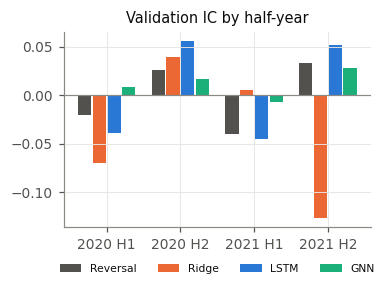

In [13]:
half = pd.Series(pd.to_datetime(dec_dates[va])).dt.year.astype(str) + np.where(pd.Series(pd.to_datetime(dec_dates[va])).dt.month <= 6, ' H1', ' H2')
period_ic = {}
for name in ['Reversal', 'Ridge', 'LSTM', 'GNN']:
    s = pd.Series(metrics[name]['val']['weekly_ic']).groupby(half.values).mean()
    period_ic[name] = s.to_dict()
pi = pd.DataFrame(period_ic)
fig, ax = plt.subplots(figsize=(3.6, 2.3))
xpos = np.arange(len(pi)); wbar = 0.2
for j, name in enumerate(pi.columns):
    ax.bar(xpos + (j - 1.5) * wbar, pi[name].values, width=wbar * 0.9, color=COLORS[name], label=name)
ax.set_xticks(xpos); ax.set_xticklabels(pi.index); ax.axhline(0, color='#8a8984', lw=0.8)
ax.set_title('Validation IC by half-year')
ax.legend(ncol=4, fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.14))
fig.savefig(f'{FIG}/ic_by_period.png'); plt.show()
RESULTS['period_ic'] = {k: {p: float(v) for p, v in d.items()} for k, d in period_ic.items()}

## 11. Save everything for the report

In [14]:
def strip(m):
    return {k: v for k, v in m.items() if k not in ('weekly_ic', 'cum_excess')}
RESULTS['metrics'] = {n: {'train': strip(m['train']), 'val': strip(m['val']),
                          **{k: m[k] for k in ('n_params', 'best_epochs') if k in m}} for n, m in metrics.items()}
RESULTS['runtime_minutes'] = {k: v['minutes'] for k, v in runs.items()}
RESULTS['total_minutes'] = (time.time() - T0) / 60
RESULTS['device'] = DEVICE
RESULTS['torch'] = torch.__version__
with open(f'{OUT}/results.json', 'w') as f:
    json.dump(RESULTS, f, indent=1, default=lambda o: o.item() if hasattr(o, 'item') else str(o))
print('Saved', f'{OUT}/results.json')
print('Figures:', sorted(os.listdir(FIG)))
print(f"Total time: {RESULTS['total_minutes']:.1f} min")

Saved /content/drive/MyDrive/Connected-Markets/results/results.json
Figures: ['example_sample.png', 'graph_adjacency.png', 'ic_by_period.png', 'learning_curves.png', 'ridge_weights.png', 'val_cumulative.png']
Total time: 0.4 min


## 12. Extra analyses requested in the proposal feedback

1. **Like-for-like ridge baseline:** ridge regression on the same 40 inputs as the LSTM (20 returns and 20 volume changes).
2. **Success relative to the LSTM-only ablation:** how often, week by week and half-year by half-year, each GNN beats the LSTM in rank IC.
3. **Qualitative check:** whether the LSTM and GNN make the same bets, and how they did in the March 2020 crash and rebound.

In [ ]:
# ---- Extra analyses requested in the proposal feedback (all numbers used in the progress report) ----
from sklearn.linear_model import Ridge
from scipy.stats import pearsonr

# 1) Ridge with the same inputs as the LSTM: 20 daily returns + 20 volume changes = 40 features
F_all = Xs.reshape(Xs.shape[0], Xs.shape[1], -1)
best = None
for alpha in [0.1, 1, 10, 100, 1000, 1e4, 1e5]:
    m = Ridge(alpha=alpha).fit(F_all[tr].reshape(-1, F_all.shape[2]), y_rank[tr].ravel())
    p = m.predict(F_all.reshape(-1, F_all.shape[2])).reshape(y_rank.shape)
    ic = evaluate(p, va)['ic']
    if best is None or ic > best[0]: best = (ic, alpha, p)
_, alpha_rv, preds['Ridge, returns + volume'] = best
v, t = evaluate(preds['Ridge, returns + volume'], va), evaluate(preds['Ridge, returns + volume'], tr)
print(f"Ridge, returns + volume (alpha {alpha_rv:g}): train IC {t['ic']:+.4f} | val IC {v['ic']:+.4f} (t={v['ic_t']:+.2f}) | "
      f"acc {v['acc']:.3f} | excess/yr {v['excess_ann']:+.1%} | Sharpe {v['sharpe']:+.2f} | net Sharpe {v['sharpe_net']:+.2f}")

# 2) Success relative to the LSTM-only ablation: how consistently does each GNN beat it?
vd = pd.to_datetime(dec_dates[va])
halves = vd.year.astype(str) + np.where(vd.month <= 6, ' H1', ' H2')
ic_lstm = np.array(metrics['LSTM']['val']['weekly_ic'])
for name in ['GNN', 'GNN (sector only)', 'GNN (correlation only)']:
    gap = np.array(metrics[name]['val']['weekly_ic']) - ic_lstm
    by_half = pd.Series(gap).groupby(halves).mean()
    print(f"{name:24s} beats the LSTM in {np.mean(gap > 0):.0%} of weeks and {int((by_half > 0).sum())} of {len(by_half)} half-years "
          f"(t-stat of the weekly IC gap {gap.mean() / gap.std() * np.sqrt(len(gap)):.1f})")

# 3) Qualitative: do the two models make the same bets, and how did they do in the March 2020 crash and rebound?
ic_gnn = np.array(metrics['GNN']['val']['weekly_ic'])
avg_stock = np.expm1(y_ret[va]).mean(1)
print(f"\nWeekly IC correlation LSTM vs GNN: {pearsonr(ic_lstm, ic_gnn)[0]:.2f} | "
      f"std LSTM {ic_lstm.std():.2f}, GNN {ic_gnn.std():.2f} | GNN IC vs average stock return: {pearsonr(ic_gnn, avg_stock)[0]:.2f}")
labels = [d.strftime('%Y-%m-%d') for d in vd]
for d, what in [('2020-03-06', 'COVID crash'), ('2020-03-20', 'rebound')]:
    i = labels.index(d)
    print(f"Week after {d} ({what}): average stock {avg_stock[i]:+.1%} | IC LSTM {ic_lstm[i]:+.2f}, GNN {ic_gnn[i]:+.2f}")